In [2]:
#@title Run on TensorFlow 2.x and import modules
%tensorflow_version 2.x
from __future__ import absolute_import, division, print_function, unicode_literals#@title Import relevant modules
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
from matplotlib import pyplot as plt
import seaborn as sns

# The following lines adjust the granularity of reporting. 
pd.options.display.max_rows = 10
pd.options.display.float_format = "{:.1f}".format

print("Imported modules.")

Imported modules.


In [4]:
#@title Load the Dataset
train_df = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/california_housing_train.csv")
train_df = train_df.reindex(np.random.permutation(train_df.index)) # shuffle the examples
test_df = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/california_housing_test.csv")

In [5]:
#@title Convert raw values to their Z-scores 
# Calculate the Z-scores of each column in the training set:
train_df_mean = train_df.mean()
train_df_std = train_df.std()
train_df_norm = (train_df - train_df_mean)/train_df_std

# Calculate the Z-scores of each column in the test set.
test_df_mean = test_df.mean()
test_df_std = test_df.std()
test_df_norm = (test_df - test_df_mean)/test_df_std

print("Normalized the values.")

Normalized the values.


In [6]:
#@title Aşağıda 3 değişken içeren bir özellik katmanı oluşturduk
#Create an empty list that will eventually hold all created feature columns.
feature_columns = []

# We scaled all the columns, including latitude and longitude, into their
# Z scores. So, instead of picking a resolution in degrees, we're going
# to use resolution_in_Zs.  A resolution_in_Zs of 1 corresponds to 
# a full standard deviation. 
resolution_in_Zs = 0.3  # 3/10 of a standard deviation. #yani 1.3-1.6 gibi
#katlar ile gidecek 

# Create a bucket feature column for latitude.
latitude_as_a_numeric_column = tf.feature_column.numeric_column("latitude")
latitude_boundaries = list(np.arange(int(min(train_df_norm['latitude'])), 
                                     int(max(train_df_norm['latitude'])), 
                                     resolution_in_Zs)) 
latitude = tf.feature_column.bucketized_column(latitude_as_a_numeric_column, latitude_boundaries)
#yukarıdaki işlemi longitude için de yapıyoruz 
# Create a bucket feature column for longitude.
longitude_as_a_numeric_column = tf.feature_column.numeric_column("longitude")
longitude_boundaries = list(np.arange(int(min(train_df_norm['longitude'])), 
                                      int(max(train_df_norm['longitude'])), 
                                      resolution_in_Zs))
longitude = tf.feature_column.bucketized_column(longitude_as_a_numeric_column, 
                                                longitude_boundaries)

# Create a feature cross of latitude and longitude.
latitude_x_longitude = tf.feature_column.crossed_column([latitude, longitude], hash_bucket_size=100)
crossed_feature = tf.feature_column.indicator_column(latitude_x_longitude)
feature_columns.append(crossed_feature)  

# Represent median_income as a floating-point value.
median_income = tf.feature_column.numeric_column("median_income")
feature_columns.append(median_income)

# Represent population as a floating-point value.
population = tf.feature_column.numeric_column("population")
feature_columns.append(population)
#ihtiyacımız olan değişkenleri numeric hale getirdikten ve crossladıktan 
#sonra bunları katman haline getiriyoruz.
# Convert the list of feature columns into a layer that will later be fed into
# the model. 
my_feature_layer = tf.keras.layers.DenseFeatures(feature_columns)

#Build a linear regression model as a baseline

In [7]:
#@title Define the plotting function.

def plot_the_loss_curve(epochs, mse):
  """Plot a curve of loss vs. epoch."""

  plt.figure()
  plt.xlabel("Epoch")
  plt.ylabel("Mean Squared Error")

  plt.plot(epochs, mse, label="Loss")
  plt.legend()
  plt.ylim([mse.min()*0.95, mse.max() * 1.03])
  plt.show()  

print("Defined the plot_the_loss_curve function.")

Defined the plot_the_loss_curve function.


In [8]:
#@title Define functions to create and train a linear regression model
def create_model(my_learning_rate, feature_layer):
  """Create and compile a simple linear regression model."""
  # Most simple tf.keras models are sequential.
  model = tf.keras.models.Sequential()

  # Add the layer containing the feature columns to the model.
  model.add(feature_layer)

  # Add one linear layer to the model to yield a simple linear regressor.
  model.add(tf.keras.layers.Dense(units=1, input_shape=(1,)))

  # Construct the layers into a model that TensorFlow can execute.
  model.compile(optimizer=tf.keras.optimizers.RMSprop(lr=my_learning_rate),
                loss="mean_squared_error",
                metrics=[tf.keras.metrics.MeanSquaredError()])

  return model           


def train_model(model, dataset, epochs, batch_size, label_name):
  """Feed a dataset into the model in order to train it."""

  # Split the dataset into features and label.
  features = {name:np.array(value) for name, value in dataset.items()}
  label = np.array(features.pop(label_name))
  history = model.fit(x=features, y=label, batch_size=batch_size,
                      epochs=epochs, shuffle=True)

  # Get details that will be useful for plotting the loss curve.
  epochs = history.epoch
  hist = pd.DataFrame(history.history)
  rmse = hist["mean_squared_error"]

  return epochs, rmse   

print("Defined the create_model and train_model functions.")

Defined the create_model and train_model functions.


 Not: Etiket dahil tüm girdi verilerini ölçeklendirdiğimiz için, ortaya çıkan kayıp değerleri önceki modellerden çok daha az olacaktır
 

Epoch 1/15
17/17 [==============================] - 1s 4ms/step - loss: 0.6764 - mean_squared_error: 0.6764
Epoch 2/15
17/17 [==============================] - 0s 3ms/step - loss: 0.4791 - mean_squared_error: 0.4791
Epoch 3/15
17/17 [==============================] - 0s 3ms/step - loss: 0.4044 - mean_squared_error: 0.4044
Epoch 4/15
17/17 [==============================] - 0s 3ms/step - loss: 0.3766 - mean_squared_error: 0.3766
Epoch 5/15
17/17 [==============================] - 0s 4ms/step - loss: 0.3673 - mean_squared_error: 0.3673
Epoch 6/15
17/17 [==============================] - 0s 3ms/step - loss: 0.3629 - mean_squared_error: 0.3629
Epoch 7/15
17/17 [==============================] - 0s 3ms/step - loss: 0.3609 - mean_squared_error: 0.3609
Epoch 8/15
17/17 [==============================] - 0s 3ms/step - loss: 0.3599 - mean_squared_error: 0.3599
Epoch 9/15
17/17 [==============================] - 0s 4ms/step - loss: 0.3603 - mean_squared_error: 0.3603
Epoch 10/15
17/17 [=========

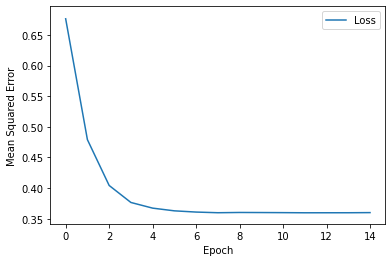


 Evaluate the linear regression model against the test set:
3/3 [==============================] - 0s 6ms/step - loss: 0.3956 - mean_squared_error: 0.3956


[0.3955886960029602, 0.3955886960029602]

In [9]:
# The following variables are the hyperparameters.
learning_rate = 0.01
epochs = 15
batch_size = 1000
label_name = "median_house_value"

# Establish the model's topography.
my_model = create_model(learning_rate, my_feature_layer)

# Train the model on the normalized training set.
epochs, mse = train_model(my_model, train_df_norm, epochs, batch_size, label_name)
plot_the_loss_curve(epochs, mse)

test_features = {name:np.array(value) for name, value in test_df_norm.items()}
test_label = np.array(test_features.pop(label_name)) # isolate the label
print("\n Evaluate the linear regression model against the test set:")
my_model.evaluate(x = test_features, y = test_label, batch_size=batch_size)

#Define a deep neural net model

In [15]:
def create_model(my_learning_rate, my_feature_layer):
  """Create and compile a simple linear regression model."""
  # Most simple tf.keras models are sequential.
  model = tf.keras.models.Sequential()

  # Add the layer containing the feature columns to the model.
  model.add(my_feature_layer)

  # Describe the topography of the model by calling the tf.keras.layers.Dense
  # method once for each layer. We've specified the following arguments:
  #   * units specifies the number of nodes in this layer.
  #   * activation specifies the activation function (Rectified Linear Unit).
  #   * name is just a string that can be useful when debugging.

  # Define the first hidden layer with 20 nodes.   
  model.add(tf.keras.layers.Dense(units=20, 
                                  activation='relu', 
                                  name='Hidden1'))
  
  # Define the second hidden layer with 12 nodes. 
  model.add(tf.keras.layers.Dense(units=12, 
                                  activation='relu', 
                                  name='Hidden2'))
  
  # Define the output layer.
  model.add(tf.keras.layers.Dense(units=1,  
                                  name='Output'))                              
  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="mean_squared_error",
                metrics=[tf.keras.metrics.MeanSquaredError()])

  return model

In [16]:
def train_model(model, dataset, epochs, label_name,
                batch_size=None):
  """Train the model by feeding it data."""

  # Split the dataset into features and label.
  features = {name:np.array(value) for name, value in dataset.items()}
  label = np.array(features.pop(label_name))
  history = model.fit(x=features, y=label, batch_size=batch_size,
                      epochs=epochs, shuffle=True) 

  # The list of epochs is stored separately from the rest of history.
  epochs = history.epoch
  
  # To track the progression of training, gather a snapshot
  # of the model's mean squared error at each epoch. 
  hist = pd.DataFrame(history.history)
  mse = hist["mean_squared_error"]

  return epochs, mse

Epoch 1/20


17/17 [==============================] - 1s 4ms/step - loss: 0.6038 - mean_squared_error: 0.6038
Epoch 2/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3714 - mean_squared_error: 0.3714
Epoch 3/20
17/17 [==============================] - 0s 5ms/step - loss: 0.3459 - mean_squared_error: 0.3459
Epoch 4/20
17/17 [==============================] - 0s 5ms/step - loss: 0.3399 - mean_squared_error: 0.3399
Epoch 5/20
17/17 [==============================] - 0s 5ms/step - loss: 0.3376 - mean_squared_error: 0.3376
Epoch 6/20
17/17 [==============================] - 0s 5ms/step - loss: 0.3352 - mean_squared_error: 0.3352
Epoch 7/20
17/17 [==============================] - 0s 6ms/step - loss: 0.3345 - mean_squared_error: 0.3345
Epoch 8/20
17/17 [==============================] - 0s 5ms/step - loss: 0.3333 - mean_squared_error: 0.3333
Epoch 9/20
17/17 [==============================] - 0s 5ms/step - loss: 0.3334 - mean_squared_error: 0.3334
Epoch 10/20
17/17 [====================

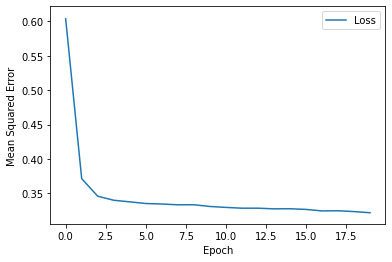


 Evaluate the new model against the test set:
3/3 [==============================] - 0s 6ms/step - loss: 0.3656 - mean_squared_error: 0.3656


[0.3655977249145508, 0.3655977249145508]

In [17]:
# The following variables are the hyperparameters.
learning_rate = 0.01
epochs = 20
batch_size = 1000

# Specify the label
label_name = "median_house_value"

# Establish the model's topography.
my_model = create_model(learning_rate, my_feature_layer)

# Train the model on the normalized training set. We're passing the entire
# normalized training set, but the model will only use the features
# defined by the feature_layer.
epochs, mse = train_model(my_model, train_df_norm, epochs, 
                          label_name, batch_size)
plot_the_loss_curve(epochs, mse)

# After building a model against the training set, test that model
# against the test set.
test_features = {name:np.array(value) for name, value in test_df_norm.items()}
test_label = np.array(test_features.pop(label_name)) # isolate the label
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x = test_features, y = test_label, batch_size=batch_size)

## Task 1: Compare the two models

How did the deep neural net perform against the baseline linear regression model?

#Task 1 Answer
actually both models are bad. But the loss of the neural network model was lower than linear model so we can say neural network model better than linear model for that sample.

## Task 2: Optimize the deep neural network's topography

Experiment with the number of layers of the deep neural network and the number of nodes in each layer.  Aim to achieve both of the following goals:

*  Lower the loss against the test set.
*  Minimize the overall number of nodes in the deep neural net. 

The two goals may be in conflict.

now i'm trying 3-3-2 nodes for 3 hidden layer as requested here (https://developers.google.com/machine-learning/crash-course/introduction-to-neural-networks/playground-exercises)

In [18]:
#@title Task 2 Answer 

def create_model1(my_learning_rate, my_feature_layer):
  """Create and compile a simple linear regression model."""
  # Most simple tf.keras models are sequential.
  model = tf.keras.models.Sequential()

  # Add the layer containing the feature columns to the model.
  model.add(my_feature_layer)

  # Describe the topography of the model by calling the tf.keras.layers.Dense
  # method once for each layer. We've specified the following arguments:
  #   * units specifies the number of nodes in this layer.
  #   * activation specifies the activation function (Rectified Linear Unit).
  #   * name is just a string that can be useful when debugging.

  # Define the first hidden layer with 3 nodes.   
  model.add(tf.keras.layers.Dense(units=3, 
                                  activation='relu', 
                                  name='Hidden1'))
  
  # Define the second hidden layer with 3 nodes. 
  model.add(tf.keras.layers.Dense(units=3, 
                                  activation='relu', 
                                  name='Hidden2'))
  # Defibe the third hidden layer with 2 nodes
  model.add(tf.keras.layers.Dense(units=2, 
                                  activation='relu', 
                                  name='Hidden3')) 
  # Define the output layer.
  model.add(tf.keras.layers.Dense(units=1,  
                                  name='Output'))                              
  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="mean_squared_error",
                metrics=[tf.keras.metrics.MeanSquaredError()])

  return model

Epoch 1/20


17/17 [==============================] - 2s 5ms/step - loss: 1.0215 - mean_squared_error: 1.0215
Epoch 2/20
17/17 [==============================] - 0s 4ms/step - loss: 1.0002 - mean_squared_error: 1.0002
Epoch 3/20
17/17 [==============================] - 0s 4ms/step - loss: 1.0000 - mean_squared_error: 1.0000
Epoch 4/20
17/17 [==============================] - 0s 4ms/step - loss: 1.0000 - mean_squared_error: 1.0000
Epoch 5/20
17/17 [==============================] - 0s 5ms/step - loss: 1.0000 - mean_squared_error: 1.0000
Epoch 6/20
17/17 [==============================] - 0s 5ms/step - loss: 1.0001 - mean_squared_error: 1.0001
Epoch 7/20
17/17 [==============================] - 0s 4ms/step - loss: 0.9999 - mean_squared_error: 0.9999
Epoch 8/20
17/17 [==============================] - 0s 4ms/step - loss: 1.0000 - mean_squared_error: 1.0000
Epoch 9/20
17/17 [==============================] - 0s 5ms/step - loss: 0.9998 - mean_squared_error: 0.9998
Epoch 10/20
17/17 [====================

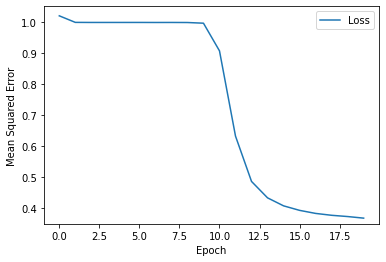


 Evaluate the new model against the test set:
3/3 [==============================] - 0s 6ms/step - loss: 0.4021 - mean_squared_error: 0.4021


[0.4021308124065399, 0.4021308124065399]

In [21]:
#@title Answer Task 2
# The following variables are the hyperparameters.
learning_rate = 0.01
epochs = 20
batch_size = 1000

# Specify the label
label_name = "median_house_value"

# Establish the model's topography.
my_model1 = create_model1(learning_rate, my_feature_layer)

# Train the model on the normalized training set. We're passing the entire
# normalized training set, but the model will only use the features
# defined by the feature_layer.
epochs, mse = train_model(my_model1, train_df_norm, epochs, 
                          label_name, batch_size)
plot_the_loss_curve(epochs, mse)

# After building a model against the training set, test that model
# against the test set.
test_features = {name:np.array(value) for name, value in test_df_norm.items()}
test_label = np.array(test_features.pop(label_name)) # isolate the label
print("\n Evaluate the new model against the test set:")
my_model1.evaluate(x = test_features, y = test_label, batch_size=batch_size)

now i'm trying 3 nodes for 1 hidden layer as requested here (https://developers.google.com/machine-learning/crash-course/introduction-to-neural-networks/playground-exercises)

In [20]:
#@title Task 2 Answer 

def create_model2(my_learning_rate, my_feature_layer):
  """Create and compile a simple linear regression model."""
  # Most simple tf.keras models are sequential.
  model = tf.keras.models.Sequential()

  # Add the layer containing the feature columns to the model.
  model.add(my_feature_layer)

  # Describe the topography of the model by calling the tf.keras.layers.Dense
  # method once for each layer. We've specified the following arguments:
  #   * units specifies the number of nodes in this layer.
  #   * activation specifies the activation function (Rectified Linear Unit).
  #   * name is just a string that can be useful when debugging.

  # Define the first hidden layer with 3 nodes.   
  model.add(tf.keras.layers.Dense(units=3, 
                                  activation='relu', 
                                  name='Hidden1'))
  
  # Define the output layer.
  model.add(tf.keras.layers.Dense(units=1,  
                                  name='Output'))                              
  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="mean_squared_error",
                metrics=[tf.keras.metrics.MeanSquaredError()])

  return model

Epoch 1/20


17/17 [==============================] - 1s 8ms/step - loss: 0.9272 - mean_squared_error: 0.9272
Epoch 2/20
17/17 [==============================] - 0s 5ms/step - loss: 0.6567 - mean_squared_error: 0.6567
Epoch 3/20
17/17 [==============================] - 0s 4ms/step - loss: 0.4306 - mean_squared_error: 0.4306
Epoch 4/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3697 - mean_squared_error: 0.3697
Epoch 5/20
17/17 [==============================] - 0s 5ms/step - loss: 0.3503 - mean_squared_error: 0.3503
Epoch 6/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3455 - mean_squared_error: 0.3455
Epoch 7/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3439 - mean_squared_error: 0.3439
Epoch 8/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3432 - mean_squared_error: 0.3432
Epoch 9/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3428 - mean_squared_error: 0.3428
Epoch 10/20
17/17 [====================

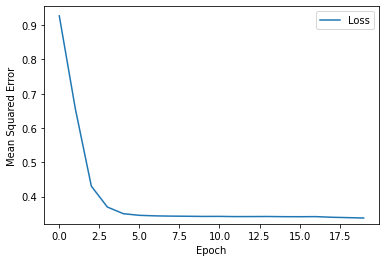


 Evaluate the new model against the test set:
3/3 [==============================] - 0s 6ms/step - loss: 0.3749 - mean_squared_error: 0.3749


[0.3748951554298401, 0.3748951554298401]

In [22]:
#@title Answer Task 2
# The following variables are the hyperparameters.
learning_rate = 0.01
epochs = 20
batch_size = 1000

# Specify the label
label_name = "median_house_value"

# Establish the model's topography.
my_model2 = create_model2(learning_rate, my_feature_layer)

# Train the model on the normalized training set. We're passing the entire
# normalized training set, but the model will only use the features
# defined by the feature_layer.
epochs, mse = train_model(my_model2, train_df_norm, epochs, 
                          label_name, batch_size)
plot_the_loss_curve(epochs, mse)

# After building a model against the training set, test that model
# against the test set.
test_features = {name:np.array(value) for name, value in test_df_norm.items()}
test_label = np.array(test_features.pop(label_name)) # isolate the label
print("\n Evaluate the new model against the test set:")
my_model2.evaluate(x = test_features, y = test_label, batch_size=batch_size)

with these parameters the model became worse. we can see it with loss score. 

In [50]:
#@title Task 2 Answer 

def create_model3(my_learning_rate, my_feature_layer):
  """Create and compile a simple linear regression model."""
  # Most simple tf.keras models are sequential.
  model = tf.keras.models.Sequential()

  # Add the layer containing the feature columns to the model.
  model.add(my_feature_layer)

  # Describe the topography of the model by calling the tf.keras.layers.Dense
  # method once for each layer. We've specified the following arguments:
  #   * units specifies the number of nodes in this layer.
  #   * activation specifies the activation function (Rectified Linear Unit).
  #   * name is just a string that can be useful when debugging.

  # Define the first hidden layer with 6 nodes.   
  model.add(tf.keras.layers.Dense(units=6, 
                                  activation='relu', 
                                  name='Hidden1'))
  # Define the second hidden layer with 4 nodes.   
  model.add(tf.keras.layers.Dense(units=4, 
                                  activation='relu', 
                                  name='Hidden2'))
  
  # Define the output layer.
  model.add(tf.keras.layers.Dense(units=1,  
                                  name='Output'))                            
  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="mean_squared_error",
                metrics=[tf.keras.metrics.MeanSquaredError()])

  return model

Epoch 1/20


17/17 [==============================] - 1s 5ms/step - loss: 0.8787 - mean_squared_error: 0.8787
Epoch 2/20
17/17 [==============================] - 0s 4ms/step - loss: 0.5296 - mean_squared_error: 0.5296
Epoch 3/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3802 - mean_squared_error: 0.3802
Epoch 4/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3505 - mean_squared_error: 0.3505
Epoch 5/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3440 - mean_squared_error: 0.3440
Epoch 6/20
17/17 [==============================] - 0s 5ms/step - loss: 0.3409 - mean_squared_error: 0.3409
Epoch 7/20
17/17 [==============================] - 0s 5ms/step - loss: 0.3386 - mean_squared_error: 0.3386
Epoch 8/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3374 - mean_squared_error: 0.3374
Epoch 9/20
17/17 [==============================] - 0s 4ms/step - loss: 0.3371 - mean_squared_error: 0.3371
Epoch 10/20
17/17 [====================

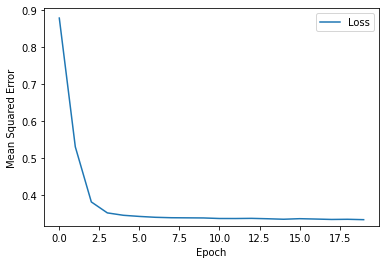


 Evaluate the new model against the test set:
3/3 [==============================] - 0s 5ms/step - loss: 0.3701 - mean_squared_error: 0.3701


[0.3700985610485077, 0.3700985610485077]

In [51]:
#@title Answer Task 2
# The following variables are the hyperparameters.
learning_rate = 0.01
epochs = 20
batch_size = 1000

# Specify the label
label_name = "median_house_value"

# Establish the model's topography.
my_model3 = create_model3(learning_rate, my_feature_layer)

# Train the model on the normalized training set. We're passing the entire
# normalized training set, but the model will only use the features
# defined by the feature_layer.
epochs, mse = train_model(my_model3, train_df_norm, epochs, 
                          label_name, batch_size)
plot_the_loss_curve(epochs, mse)

# After building a model against the training set, test that model
# against the test set.
test_features = {name:np.array(value) for name, value in test_df_norm.items()}
test_label = np.array(test_features.pop(label_name)) # isolate the label
print("\n Evaluate the new model against the test set:")
my_model3.evaluate(x = test_features, y = test_label, batch_size=batch_size)

I experimented with different layer numbers, neuron counts and different activation functions. Actually there is not much difference but last model looking better than others.So we can say 2 hidden layer first 6-4 neuron and relu activation function are better.In fact, the requests of the question also limited me and the loss value did not decrease too much.

#Task 3: Regularize the deep neural network (if you have enough time)
Notice that the model's loss against the test set is much higher than the loss against the training set. In other words, the deep neural network is overfitting to the data in the training set. To reduce overfitting, regularize the model. The course has suggested several different ways to regularize a model, including:

L1 regularization
L2 regularization
Dropout regularization
Your task is to experiment with one or more regularization mechanisms to bring the test loss closer to the training loss (while still keeping test loss relatively low).

Note: When you add a regularization function to a model, you might need to tweak other hyperparameters.

Epoch 1/140


17/17 [==============================] - 1s 5ms/step - loss: 8.0114 - mean_squared_error: 0.8587
Epoch 2/140
17/17 [==============================] - 0s 6ms/step - loss: 2.6513 - mean_squared_error: 0.5703
Epoch 3/140
17/17 [==============================] - 0s 5ms/step - loss: 1.3591 - mean_squared_error: 0.5036
Epoch 4/140
17/17 [==============================] - 0s 6ms/step - loss: 0.8859 - mean_squared_error: 0.4997
Epoch 5/140
17/17 [==============================] - 0s 5ms/step - loss: 0.7487 - mean_squared_error: 0.4823
Epoch 6/140
17/17 [==============================] - 0s 5ms/step - loss: 0.7005 - mean_squared_error: 0.4678
Epoch 7/140
17/17 [==============================] - 0s 5ms/step - loss: 0.6755 - mean_squared_error: 0.4540
Epoch 8/140
17/17 [==============================] - 0s 5ms/step - loss: 0.6590 - mean_squared_error: 0.4437
Epoch 9/140
17/17 [==============================] - 0s 6ms/step - loss: 0.6400 - mean_squared_error: 0.4346
Epoch 10/140
17/17 [===========

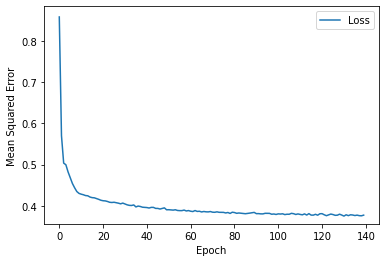


 Evaluate the new model against the test set:
3/3 [==============================] - 0s 6ms/step - loss: 0.5726 - mean_squared_error: 0.4120


[0.5726169347763062, 0.4119924306869507]

In [56]:
#@title Task 3 Answer



def create_modelL1(my_learning_rate, my_feature_layer):
  """Create and compile a simple linear regression model."""

  # Discard any pre-existing version of the model.
  model = None

  # Most simple tf.keras models are sequential.
  model = tf.keras.models.Sequential()

  # Add the layer containing the feature columns to the model.
  model.add(my_feature_layer)

  # Describe the topography of the model. 

  # Implement L1 regularization in the first hidden layer.
  model.add(tf.keras.layers.Dense(units=20, 
                                  activation='relu',
                                  kernel_regularizer=tf.keras.regularizers.l1(0.04),
                                  name='Hidden1'))
  
  # Implement L1 regularization in the second hidden layer.
  model.add(tf.keras.layers.Dense(units=12, 
                                  activation='relu', 
                                  kernel_regularizer=tf.keras.regularizers.l1(0.04),
                                  name='Hidden2'))

  # Define the output layer.
  model.add(tf.keras.layers.Dense(units=1,  
                                  name='Output'))                              
  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="mean_squared_error",
                metrics=[tf.keras.metrics.MeanSquaredError()])

  return model     

# Call the new create_model function and the other (unchanged) functions.

# The following variables are the hyperparameters.
learning_rate = 0.007
epochs = 140
batch_size = 1000

label_name = "median_house_value"

# Establish the model's topography.
my_modelL1 = create_modelL1(learning_rate, my_feature_layer)

# Train the model on the normalized training set.
epochs, mse = train_model(my_modelL1, train_df_norm, epochs, 
                          label_name, batch_size)
plot_the_loss_curve(epochs, mse)

test_features = {name:np.array(value) for name, value in test_df_norm.items()}
test_label = np.array(test_features.pop(label_name)) # isolate the label
print("\n Evaluate the new model against the test set:")
my_modelL1.evaluate(x = test_features, y = test_label, batch_size=batch_size) 

Epoch 1/140


17/17 [==============================] - 1s 5ms/step - loss: 1.8840 - mean_squared_error: 0.7494
Epoch 2/140
17/17 [==============================] - 0s 5ms/step - loss: 0.8047 - mean_squared_error: 0.4475
Epoch 3/140
17/17 [==============================] - 0s 5ms/step - loss: 0.5825 - mean_squared_error: 0.4093
Epoch 4/140
17/17 [==============================] - 0s 5ms/step - loss: 0.5062 - mean_squared_error: 0.3887
Epoch 5/140
17/17 [==============================] - 0s 5ms/step - loss: 0.4728 - mean_squared_error: 0.3788
Epoch 6/140
17/17 [==============================] - 0s 6ms/step - loss: 0.4571 - mean_squared_error: 0.3742
Epoch 7/140
17/17 [==============================] - 0s 5ms/step - loss: 0.4489 - mean_squared_error: 0.3728
Epoch 8/140
17/17 [==============================] - 0s 5ms/step - loss: 0.4432 - mean_squared_error: 0.3717
Epoch 9/140
17/17 [==============================] - 0s 5ms/step - loss: 0.4372 - mean_squared_error: 0.3712
Epoch 10/140
17/17 [===========

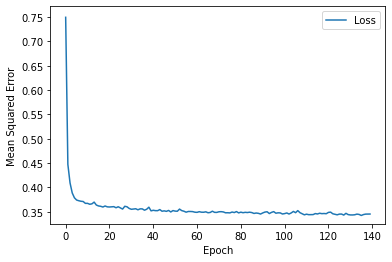


 Evaluate the new model against the test set:
3/3 [==============================] - 0s 6ms/step - loss: 0.4111 - mean_squared_error: 0.3765


[0.4111396074295044, 0.37646085023880005]

In [57]:
#@title Task 3 Answer



def create_modelL2(my_learning_rate, my_feature_layer):
  """Create and compile a simple linear regression model."""

  # Discard any pre-existing version of the model.
  model = None

  # Most simple tf.keras models are sequential.
  model = tf.keras.models.Sequential()

  # Add the layer containing the feature columns to the model.
  model.add(my_feature_layer)

  # Describe the topography of the model. 

  # Implement L2 regularization in the first hidden layer.
  model.add(tf.keras.layers.Dense(units=20, 
                                  activation='relu',
                                  kernel_regularizer=tf.keras.regularizers.l2(0.04),
                                  name='Hidden1'))
  
  # Implement L2 regularization in the second hidden layer.
  model.add(tf.keras.layers.Dense(units=12, 
                                  activation='relu', 
                                  kernel_regularizer=tf.keras.regularizers.l2(0.04),
                                  name='Hidden2'))

  # Define the output layer.
  model.add(tf.keras.layers.Dense(units=1,  
                                  name='Output'))                              
  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="mean_squared_error",
                metrics=[tf.keras.metrics.MeanSquaredError()])

  return model     

# Call the new create_model function and the other (unchanged) functions.

# The following variables are the hyperparameters.
learning_rate = 0.007
epochs = 140
batch_size = 1000

label_name = "median_house_value"

# Establish the model's topography.
my_modelL2 = create_modelL2(learning_rate, my_feature_layer)

# Train the model on the normalized training set.
epochs, mse = train_model(my_modelL2, train_df_norm, epochs, 
                          label_name, batch_size)
plot_the_loss_curve(epochs, mse)

test_features = {name:np.array(value) for name, value in test_df_norm.items()}
test_label = np.array(test_features.pop(label_name)) # isolate the label
print("\n Evaluate the new model against the test set:")
my_modelL2.evaluate(x = test_features, y = test_label, batch_size=batch_size) 

Epoch 1/140


17/17 [==============================] - 1s 5ms/step - loss: 0.7002 - mean_squared_error: 0.7002
Epoch 2/140
17/17 [==============================] - 0s 6ms/step - loss: 0.4021 - mean_squared_error: 0.4021
Epoch 3/140
17/17 [==============================] - 0s 5ms/step - loss: 0.3570 - mean_squared_error: 0.3570
Epoch 4/140
17/17 [==============================] - 0s 5ms/step - loss: 0.3463 - mean_squared_error: 0.3463
Epoch 5/140
17/17 [==============================] - 0s 6ms/step - loss: 0.3438 - mean_squared_error: 0.3438
Epoch 6/140
17/17 [==============================] - 0s 5ms/step - loss: 0.3432 - mean_squared_error: 0.3432
Epoch 7/140
17/17 [==============================] - 0s 6ms/step - loss: 0.3397 - mean_squared_error: 0.3397
Epoch 8/140
17/17 [==============================] - 0s 5ms/step - loss: 0.3395 - mean_squared_error: 0.3395
Epoch 9/140
17/17 [==============================] - 0s 7ms/step - loss: 0.3381 - mean_squared_error: 0.3381
Epoch 10/140
17/17 [===========

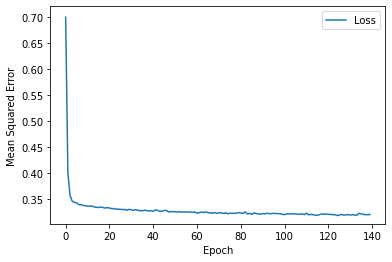


 Evaluate the new model against the test set:
3/3 [==============================] - 0s 8ms/step - loss: 0.3636 - mean_squared_error: 0.3636


[0.3636060357093811, 0.3636060357093811]

In [58]:
#@title Task 3 Answer



def create_modeldrop(my_learning_rate, my_feature_layer):
  """Create and compile a simple linear regression model."""

  # Discard any pre-existing version of the model.
  model = None

  # Most simple tf.keras models are sequential.
  model = tf.keras.models.Sequential()

  # Add the layer containing the feature columns to the model.
  model.add(my_feature_layer)

  # Describe the topography of the model. 

  model.add(tf.keras.layers.Dense(units=20, 
                                  activation='relu',
                                  name='Hidden1'))
  #Implement dropout regularization
  model.add(tf.keras.layers.Dropout(rate=0.05))
  model.add(tf.keras.layers.Dense(units=12, 
                                  activation='relu',
                                  name='Hidden2'))

  # Define the output layer.
  model.add(tf.keras.layers.Dense(units=1,  
                                  name='Output'))                              
  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="mean_squared_error",
                metrics=[tf.keras.metrics.MeanSquaredError()])

  return model     

# Call the new create_model function and the other (unchanged) functions.

# The following variables are the hyperparameters.
learning_rate = 0.007
epochs = 140
batch_size = 1000

label_name = "median_house_value"

# Establish the model's topography.
my_modeldrop = create_modeldrop(learning_rate, my_feature_layer)

# Train the model on the normalized training set.
epochs, mse = train_model(my_modeldrop, train_df_norm, epochs, 
                          label_name, batch_size)
plot_the_loss_curve(epochs, mse)

test_features = {name:np.array(value) for name, value in test_df_norm.items()}
test_label = np.array(test_features.pop(label_name)) # isolate the label
print("\n Evaluate the new model against the test set:")
my_modeldrop.evaluate(x = test_features, y = test_label, batch_size=batch_size) 

we can see dropout looking better than others.But we also will try another numbers of hidden layer and neuron. 

#https://developers.google.com/machine-learning/crash-course/introduction-to-neural-networks/playground-exercises ABOUT TASK 1 AND TASK 2

Task 1: The model as given combines our two input features into a single neuron. Will this model learn any nonlinearities? Run it to confirm your guess.

Answer: I think it is very difficult to learn because our sample does not have linear distribution and we have to try more parameters and methods to learn such examples. When we run the system, we can see from the loss values that you cannot learn.

Task 2: Try increasing the number of neurons in the hidden layer from 1 to 2, and also try changing from a Linear activation to a nonlinear activation like ReLU. Can you create a model that can learn nonlinearities? Can it model the data effectively?

Answer:actually, this one is better than the other, but this is insufficient, I think the reason for this is the low number of hidden layers. Better model can be created with different number of hidden layers, number of neurons and even activation functions